# HW2 – Convergence uniforme et limites de l'apprentissage
**Statistical and Machine Learning – M2 IMDS (UHA)**

Dans ce notebook, on simule directement les lois de probabilité qui apparaissent dans les résultats théoriques du cours, puis on compare les simulations avec les formules.

**Plan**
- Partie I (Q1 à Q5) : convergence uniforme, avec des variables binomiales.
- Partie II (Q6 à Q8) : No-Free-Lunch, avec des cibles complètement aléatoires.
- Partie III (Q9 et Q10) : connaissance a priori, avec des cibles de type seuil.
- Q11 : conclusion.

**Choix des paramètres**
- On utilise seulement `numpy` et `matplotlib`. La graine du générateur aléatoire est fixée (2026), donc les résultats sont reproductibles.
- Nombre de répétitions Monte-Carlo (`n_rep`) : entre 1 000 et 20 000 selon la question. Une probabilité $q$ estimée avec `n_rep` répétitions a une erreur de simulation d'environ $\sqrt{q(1-q)/n_{rep}}$, soit au plus 0.011 pour 2 000 répétitions et 0.0035 pour 20 000. Les écarts plus petits que cela ne sont pas significatifs.
- Partie I : $\varepsilon = 0.1$ pour la plupart des questions (et $\varepsilon = 0.2$ en plus à la Q5), $\delta = 0.05$, tailles de classe $|H| \in \{5, 10, 50, 100, 500\}$, tailles d'échantillon $m$ de 5 à 600.
- Parties II et III : taille du domaine $N = 100$ (et $N \in \{10, 50, 200\}$ à la Q6), $m$ de 0 à 300.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)      # graine fixée pour retrouver les mêmes résultats
plt.rcParams["figure.figsize"] = (10, 4)

---
# Partie I – Simulation de la convergence uniforme

Notations : $H = \{h_1, \dots, h_K\}$, $L_D(h_j) = p_j$, et le nombre d'erreurs sur l'échantillon vérifie $E_j \sim \text{Bin}(m, p_j)$, donc $L_S(h_j) = E_j / m$.

In [2]:
def proba_sup(m, p, eps, n_rep):
    """Estime Pr[ max_j |LS(h_j) - p_j| > eps ] pour un échantillon de taille m.
    p = tableau des vraies erreurs p_j (une seule valeur si on étudie une seule hypothèse)."""
    E = rng.binomial(m, p, size=(n_rep, len(p)))     # E_j ~ Bin(m, p_j) : n_rep lignes, K colonnes
    delta_S = np.abs(E / m - p).max(axis=1)           # Delta_S pour chaque répétition
    return np.mean(delta_S > eps + 1e-9)              # 1e-9 : évite les erreurs d'arrondi sur le ">"

## Question 1 – Le risque empirique comme variable aléatoire

**Méthode.** Pour $p \in \{0.1, 0.3, 0.5\}$ et $m \in \{10, 50, 200, 1000\}$, on simule 10 000 fois $E \sim \text{Bin}(m, p)$ et on calcule $L_S = E/m$.

**Théorie.** $\mathbb{E}[L_S] = p$ et $\text{Var}(L_S) = p(1-p)/m$.

In [ ]:
p_list = [0.1, 0.3, 0.5]          # vraies erreurs de trois hypothèses
m_list = [10, 50, 200, 1000]      # tailles d'échantillon
n_rep = 10000                     # répétitions Monte-Carlo

print("    p      m    moyenne LS   écart-type simulé   écart-type théorique")
for p in p_list:
    for m in m_list:
        E = rng.binomial(m, p, size=n_rep)    # nombre d'erreurs sur chaque échantillon
        LS = E / m                            # risque empirique
        print(f"{p:5.2f} {m:6d} {LS.mean():12.4f} {LS.std():14.4f} {np.sqrt(p*(1-p)/m):18.4f}")

    p      m    moyenne LS   écart-type simulé   écart-type théorique
 0.10     10       0.1016         0.0960             0.0949
 0.10     50       0.0996         0.0420             0.0424
 0.10    200       0.0997         0.0213             0.0212
 0.10   1000       0.1001         0.0094             0.0095
 0.30     10       0.2988         0.1451             0.1449
 0.30     50       0.3001         0.0655             0.0648
 0.30    200       0.3001         0.0322             0.0324
 0.30   1000       0.3001         0.0145             0.0145
 0.50     10       0.4987         0.1567             0.1581
 0.50     50       0.5004         0.0706             0.0707
 0.50    200       0.5000         0.0349             0.0354
 0.50   1000       0.5000         0.0158             0.0158


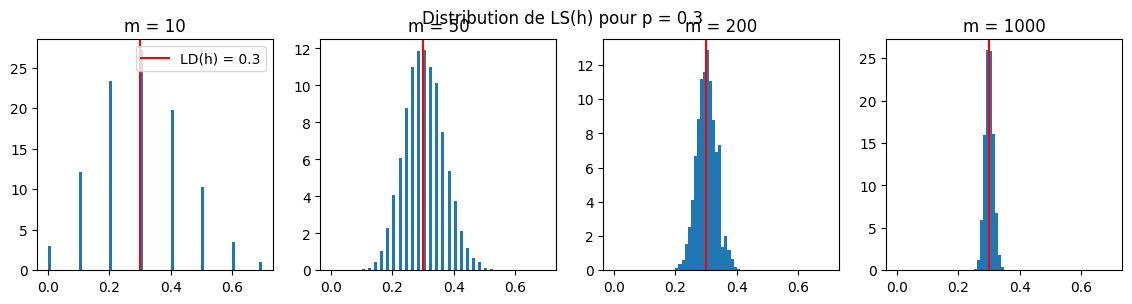

In [ ]:
p = 0.3
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True)
for ax, m in zip(axes, m_list):
    LS = rng.binomial(m, p, size=n_rep) / m
    ax.hist(LS, bins=np.linspace(0, 0.7, 71), density=True)
    ax.axvline(p, color="red", label="LD(h) = 0.3")
    ax.set_title(f"m = {m}")
axes[0].legend()
plt.suptitle("Distribution de LS(h) pour p = 0.3")
plt.show()

**Commentaire.**
- La moyenne simulée est très proche de $p$  : $L_S(h)$ est un estimateur sans biais de $L_D(h)$.
- L'écart-type simulé colle à $\sqrt{p(1-p)/m}$. Par exemple pour $p = 0.3$ : 0.145 ($m=10$), 0.066 ($m=50$), 0.032 ($m=200$), 0.0145 ($m=1000$). Multiplier $m$ par 100 divise l'écart-type par 10.
- Sur les histogrammes, pour $m = 10$ la loi est très étalée et discrète. Pour $m = 1000$, c'est une cloche étroite autour de 0.3 (on reconnaît le théorème central limite).
- Donc quand $m$ augmente, $L_S(h)$ se concentre de plus en plus autour de $L_D(h)$.

## Question 2 – Écart entre risque empirique et risque vrai

**Méthode.** On prend une hypothèse avec $p = 0.3$ et $\varepsilon = 0.1$. Pour chaque $m$ (de 5 à 300), on estime $\Pr[|L_S(h) - L_D(h)| > \varepsilon]$ sur 20 000 échantillons et on la compare à la borne de Hoeffding $2e^{-2m\varepsilon^2}$ (coupée à 1, puisqu'une probabilité ne dépasse pas 1).

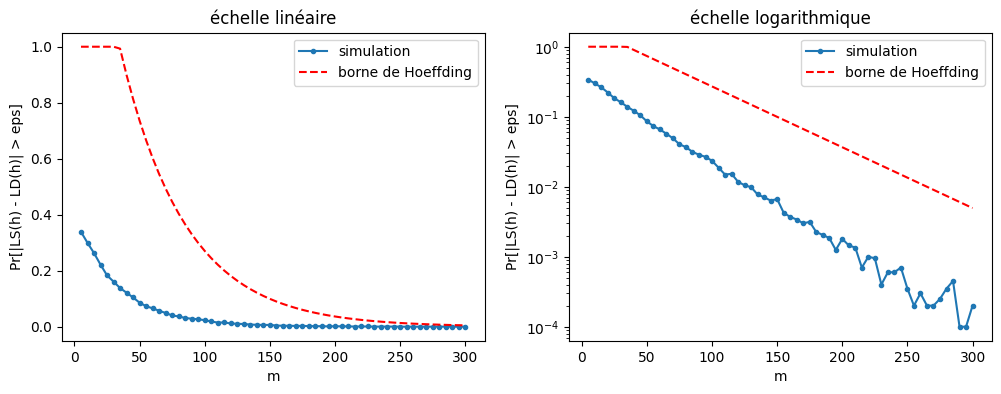

   m    simulation    Hoeffding    rapport borne/simulation
  10       0.2997       1.0000            3.3
  25       0.1834       1.0000            5.5
  50       0.0859       0.7358            8.6
 100       0.0234       0.2707           11.5
 150       0.0066       0.0996           15.0
 200       0.0018       0.0366           20.4


In [ ]:
p = np.array([0.3])            # une seule hypothèse
eps = 0.1
n_rep = 20000
m_list = np.arange(5, 301, 5)

proba_exp = np.array([proba_sup(m, p, eps, n_rep) for m in m_list])
hoeffding = np.minimum(1, 2 * np.exp(-2 * m_list * eps**2))     # on coupe à 1 (une proba ne dépasse pas 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax in axes:
    ax.plot(m_list, proba_exp, "o-", markersize=3, label="simulation")
    ax.plot(m_list, hoeffding, "r--", label="borne de Hoeffding")
    ax.set_xlabel("m")
    ax.set_ylabel("Pr[|LS(h) - LD(h)| > eps]")
    ax.legend()
axes[0].set_title("échelle linéaire")
axes[1].set_yscale("log")
axes[1].set_title("échelle logarithmique")
plt.show()

print("   m    simulation    Hoeffding    rapport borne/simulation")
for m in [10, 25, 50, 100, 150, 200]:
    i = np.where(m_list == m)[0][0]
    print(f"{m:4d} {proba_exp[i]:12.4f} {hoeffding[i]:12.4f} {hoeffding[i]/max(proba_exp[i],1e-12):14.1f}")

**Commentaire.**
- La probabilité simulée décroît de façon exponentielle en $m$ (c'est presque une droite en échelle logarithmique) : 0.30 pour $m=10$, 0.086 pour $m=50$, 0.023 pour $m=100$, 0.0018 pour $m=200$.
- La borne de Hoeffding est toujours au-dessus de la simulation : elle est donc valide. Mais elle est **conservative** : elle vaut 1 (donc inutile) pour $m \le 34$, et pour $m = 200$ elle est environ 20 fois trop grande (0.037 contre 0.0018).
- L'écart entre les deux courbes augmente avec $m$. Deux raisons : Hoeffding suppose seulement que les variables sont dans $[0,1]$ (cas le pire, variance $1/4$), alors qu'ici la variance vaut $p(1-p) = 0.21$ ; et il perd aussi un facteur polynomial devant l'exponentielle (approximation gaussienne).
- La borne n'est donc pas exacte, mais elle a la bonne forme : décroissance exponentielle en $m\varepsilon^2$.

## Question 3 – D'une hypothèse à la convergence uniforme

**Méthode.** On prend $K = 50$ hypothèses dont les vraies erreurs $p_j$ sont tirées une fois pour toutes uniformément dans $[0.1, 0.9]$. Pour chaque $m$, on simule 2 000 échantillons : on tire $E_j \sim \text{Bin}(m, p_j)$ pour les 50 hypothèses et on calcule $\Delta_S = \max_j |L_S(h_j) - p_j|$. On estime $\Pr[\Delta_S > \varepsilon]$ avec $\varepsilon = 0.1$ et on compare à $2|H| e^{-2m\varepsilon^2}$.

(Dans cette simulation les $E_j$ sont indépendants, comme dans l'énoncé. Dans un vrai problème ils dépendent du même échantillon, mais la borne de l'union reste valable dans tous les cas.)

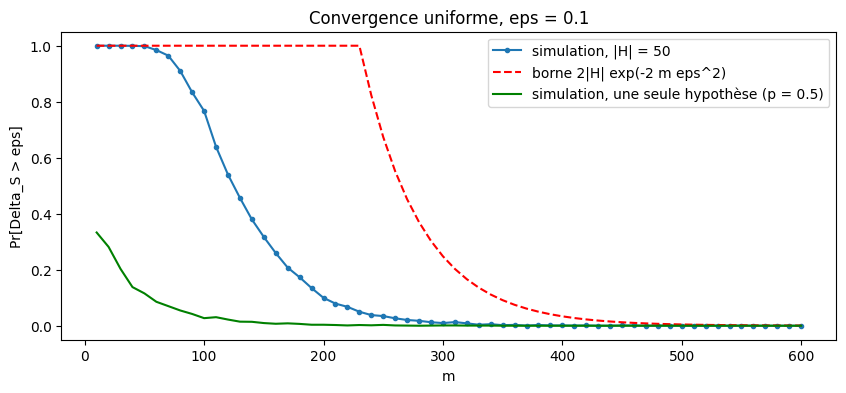

   m   simulation   borne
  50     0.9985   1.0000
 100     0.7670   1.0000
 150     0.3170   1.0000
 200     0.0995   1.0000
 250     0.0345   0.6738
 300     0.0095   0.2479
 400     0.0010   0.0335


In [ ]:
K = 50
p_all = rng.uniform(0.1, 0.9, 500)    # vraies erreurs de 500 hypothèses (on prendra les K premières)
p = p_all[:K]
eps = 0.1
n_rep = 2000
m_list = np.arange(10, 601, 10)

proba_unif = np.array([proba_sup(m, p, eps, n_rep) for m in m_list])
borne_unif = np.minimum(1, 2 * K * np.exp(-2 * m_list * eps**2))
# pour comparer : une seule hypothèse (p = 0.5, le pire cas)
proba_une = np.array([proba_sup(m, np.array([0.5]), eps, n_rep) for m in m_list])

plt.plot(m_list, proba_unif, "o-", markersize=3, label=f"simulation, |H| = {K}")
plt.plot(m_list, borne_unif, "r--", label="borne 2|H| exp(-2 m eps^2)")
plt.plot(m_list, proba_une, "g-", label="simulation, une seule hypothèse (p = 0.5)")
plt.xlabel("m")
plt.ylabel("Pr[Delta_S > eps]")
plt.legend()
plt.title(f"Convergence uniforme, eps = {eps}")
plt.show()

print("   m   simulation   borne")
for m in [50, 100, 150, 200, 250, 300, 400]:
    i = np.where(m_list == m)[0][0]
    print(f"{m:4d} {proba_unif[i]:10.4f} {borne_unif[i]:8.4f}")

**Commentaire.**
- Pour $m$ petit, il est presque certain qu'au moins une des 50 hypothèses est mal estimée : $\Pr[\Delta_S > \varepsilon] = 0.9985$ pour $m = 50$, 0.77 pour $m = 100$, 0.10 pour $m = 200$. La courbe pour une seule hypothèse (en vert) tombe beaucoup plus tôt : contrôler toutes les hypothèses en même temps demande plus de données.
- La borne $2|H|e^{-2m\varepsilon^2}$ vaut plus de 1 (donc elle ne dit rien) jusqu'à $m \approx \ln(100)/0.02 \approx 230$. Ensuite elle est valide mais conservative : pour $m = 250$, 0.0345 (simulation) contre 0.67 (borne) ; pour $m = 400$, 0.0010 contre 0.034. Elle est donc 20 à 30 fois trop grande.
- Aux défauts de Hoeffding (Q2) s'ajoute la borne de l'union : elle additionne les probabilités des 50 événements « $h_j$ est mal estimée », alors que seules les hypothèses avec $p_j$ proche de 0.5 ont une vraie chance de dévier.

## Question 4 – Effet de la taille de la classe d'hypothèses

**Méthode.** On fixe $\varepsilon = 0.1$ et on refait l'expérience pour $|H| \in \{5, 10, 50, 100, 500\}$ (les classes sont emboîtées : on prend les $|H|$ premières valeurs de $p_j$). On trace $\Pr[\Delta_S > \varepsilon]$ en fonction de $m$, à gauche par simulation (2 000 répétitions), à droite avec la borne théorique.

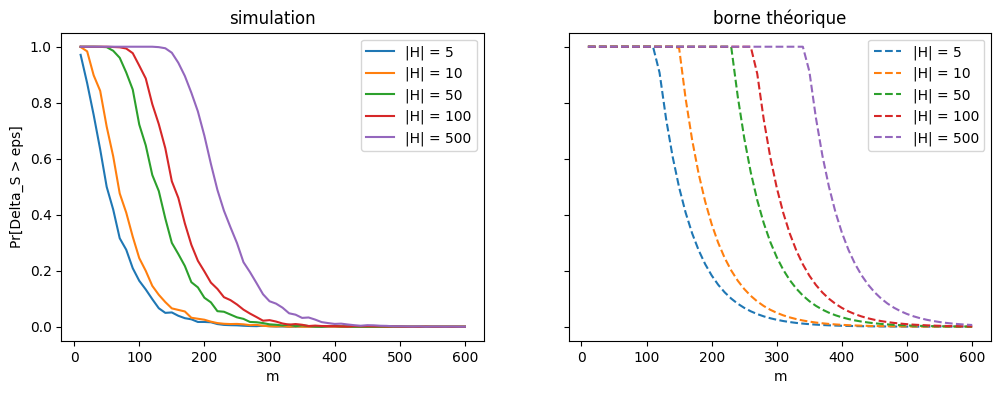

In [ ]:
K_list = [5, 10, 50, 100, 500]
eps = 0.1
n_rep = 2000
m_list = np.arange(10, 601, 10)

resultats = {}                     # resultats[K] = probabilités simulées pour chaque m
for K in K_list:
    resultats[K] = np.array([proba_sup(m, p_all[:K], eps, n_rep) for m in m_list])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for K in K_list:
    ligne = axes[0].plot(m_list, resultats[K], label=f"|H| = {K}")
    axes[1].plot(m_list, np.minimum(1, 2 * K * np.exp(-2 * m_list * eps**2)), "--", color=ligne[0].get_color(), label=f"|H| = {K}")
axes[0].set_title("simulation")
axes[1].set_title("borne théorique")
for ax in axes:
    ax.set_xlabel("m")
    ax.legend()
axes[0].set_ylabel("Pr[Delta_S > eps]")
plt.show()

**Commentaire.**
- *Effet de $|H|$ sur la convergence uniforme.* Plus $|H|$ est grand, plus la courbe est décalée vers la droite : pour un $m$ donné, il y a plus de chances qu'au moins une hypothèse soit mal estimée, donc la convergence uniforme est plus lente.
- *Faut-il plus de données ?* Oui, une classe plus grande demande en général plus de données, mais pas proportionnellement. Quand $|H|$ est multiplié par 100 (de 5 à 500), le $m$ nécessaire pour descendre sous 5 % passe seulement de 140 à 330 (voir Q5), soit un facteur 2.4.
- *Lien avec $\log|H|$.* La borne donne $m \ge \ln(2|H|/\delta)/(2\varepsilon^2)$ : $|H|$ n'intervient que par son logarithme. Chaque fois que $|H|$ est multiplié par 10, la théorie ajoute toujours le même nombre d'exemples ($\ln 10/(2\varepsilon^2) \approx 115$ pour $\varepsilon = 0.1$). On le voit dans les simulations : les courbes pour $|H| = 5, 50, 500$ sont à peu près régulièrement espacées (140, puis 240, puis 330 exemples pour passer sous 5 %). La raison est que la probabilité décroît exponentiellement en $m$, ce qui compense très bien le facteur $|H|$ devant l'exponentielle.

## Question 5 – Complexité d'échantillon expérimentale

**Méthode.** On fixe $\delta = 0.05$ et deux valeurs de $\varepsilon$ : 0.1 et 0.2. Pour chaque $|H|$, on cherche le plus petit $m$ de la grille testée (pas de 10 pour $\varepsilon = 0.1$, pas de 5 pour $\varepsilon = 0.2$) tel que $\Pr[\Delta_S > \varepsilon] \le \delta$, et on le compare à la valeur suffisante $\lceil \ln(2|H|/\delta)/(2\varepsilon^2) \rceil$.

eps = 0.1, delta = 0.05
  |H|   m expérimental   m théorique   rapport théorique/expérimental
    5            140            265               1.89
   10            180            300               1.67
   50            240            381               1.59
  100            270            415               1.54
  500            330            496               1.50

eps = 0.2, delta = 0.05


  |H|   m expérimental   m théorique   rapport théorique/expérimental
    5             40             67               1.68
   10             45             75               1.67
   50             60             96               1.60
  100             65            104               1.60
  500             85            124               1.46


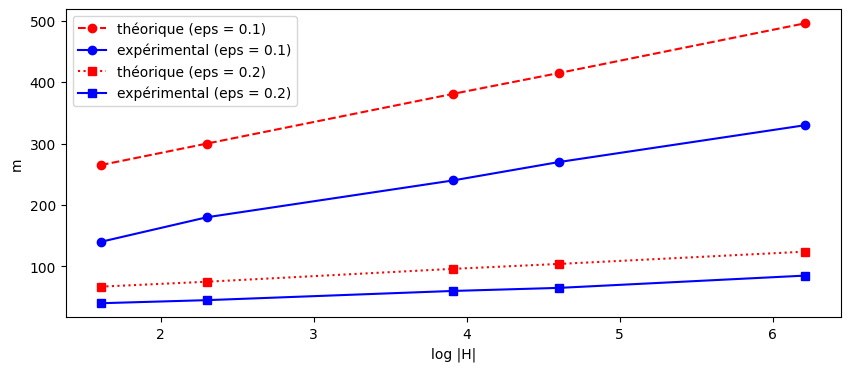

In [ ]:
def m_minimum(courbes, m_list, eps, delta):
    """Pour chaque |H|, plus petit m testé avec Pr[Delta_S > eps] <= delta, et m théorique."""
    m_exp_list, m_th_list = [], []
    print("  |H|   m expérimental   m théorique   rapport théorique/expérimental")
    for K in K_list:
        ok = np.where(courbes[K] <= delta)[0]
        m_exp = m_list[ok[0]]                                        # première valeur de la grille qui convient
        m_th = int(np.ceil(np.log(2 * K / delta) / (2 * eps**2)))    # borne suffisante
        m_exp_list.append(m_exp)
        m_th_list.append(m_th)
        print(f"{K:5d} {m_exp:14d} {m_th:14d} {m_th/m_exp:18.2f}")
    return m_exp_list, m_th_list

# Réglage 1 : eps = 0.1, delta = 0.05 (on réutilise les courbes de la question 4)
print("eps = 0.1, delta = 0.05")
m_exp1, m_th1 = m_minimum(resultats, m_list, 0.1, 0.05)

# Réglage 2 : eps = 0.2, delta = 0.05 (grille plus fine car m est plus petit)
print()
print("eps = 0.2, delta = 0.05")
m_list2 = np.arange(5, 201, 5)
courbes2 = {K: np.array([proba_sup(m, p_all[:K], 0.2, n_rep) for m in m_list2]) for K in K_list}
m_exp2, m_th2 = m_minimum(courbes2, m_list2, 0.2, 0.05)

# m en fonction de log|H|
logK = np.log(K_list)
plt.plot(logK, m_th1, "r--o", label="théorique (eps = 0.1)")
plt.plot(logK, m_exp1, "bo-", label="expérimental (eps = 0.1)")
plt.plot(logK, m_th2, "r:s", label="théorique (eps = 0.2)")
plt.plot(logK, m_exp2, "bs-", label="expérimental (eps = 0.2)")
plt.xlabel("log |H|")
plt.ylabel("m")
plt.legend()
plt.show()

**Commentaire.**
- Le $m$ théorique est toujours plus grand que le $m$ expérimental, d'un facteur 1.5 à 1.9 pour $\varepsilon = 0.1$ (et 1.5 à 1.7 pour $\varepsilon = 0.2$). C'est normal : le théorème donne une **condition suffisante** : si $m \ge m_{th}$, alors $\Pr[\Delta_S > \varepsilon] \le \delta$ pour *n'importe quelle* classe de cette taille et *n'importe quelles* vraies erreurs.
- Ici, nos $p_j$ sont particuliers (variance $p(1-p) < 1/4$ pour la plupart), alors que la borne (Hoeffding + union) est faite pour le cas le pire. Elle peut donc être trop prudente, et elle n'a aucune raison d'être le plus petit $m$ qui marche.
- Le $m$ expérimental est aussi approximatif : il est lu sur une grille, et la probabilité simulée est connue à $\pm 0.01$ environ, donc $m_{exp}$ est connu à une dizaine d'exemples près.
- Les deux courbes sont à peu près des droites en fonction de $\ln|H|$ (la pente théorique est $1/(2\varepsilon^2)$ : 50 pour $\varepsilon = 0.1$, 12.5 pour $\varepsilon = 0.2$ ; les pentes expérimentales sont un peu plus faibles). Et quand $\varepsilon$ est multiplié par 2, $m$ est divisé par environ 4 (théorie : 265 à 67 pour $|H|=5$ ; simulation : 140 à 40), ce qui confirme la dépendance en $1/\varepsilon^2$.

---
# Partie II – Simulation du No-Free-Lunch

Domaine fini $X = \{1, \dots, N\}$ avec la loi uniforme. À chaque répétition, on tire une nouvelle cible $f$ avec $f(x) \sim \text{Bernoulli}(1/2)$ indépendamment pour chaque $x$. L'algorithme d'apprentissage est la mémorisation : on prédit le label observé si $x$ est dans l'échantillon, et 0 sinon.

(Dans le code, les points sont numérotés de $0$ à $N-1$ au lieu de $1$ à $N$, ce qui ne change rien.)

## Question 6 – Points vus et non vus

**Méthode.** Pour $N \in \{10, 50, 100, 200\}$ et $m$ de 0 à 400, on répète 1 000 fois : (a) on tire $f$, (b) on tire $m$ points uniformément, (c) on calcule la fraction de points de $X$ jamais tirés. On compare la moyenne à $(1 - 1/N)^m$.

**Pourquoi c'est aussi l'espérance de la fraction.** Soit $U_x = \mathbf{1}[x \text{ non vu}]$. La fraction de points non vus est $\frac{1}{N}\sum_x U_x$. Par linéarité de l'espérance,
$$\mathbb{E}\Big[\frac{1}{N}\sum_x U_x\Big] = \frac{1}{N}\sum_x \Pr[x \text{ non vu}] = \frac{1}{N} \cdot N \cdot \Big(1 - \frac{1}{N}\Big)^m = \Big(1 - \frac{1}{N}\Big)^m,$$
car les $m$ tirages sont indépendants et chacun évite $x$ avec probabilité $1 - 1/N$. (Les $U_x$ ne sont pas indépendants entre eux, mais la linéarité de l'espérance n'a pas besoin de cette propriété.)

   N      m   fraction simulée   (1-1/N)^m


  10     20         0.1244         0.1216
  10    100         0.0000         0.0000
  10    200         0.0000         0.0000


  50     20         0.6674         0.6676
  50    100         0.1317         0.1326
  50    200         0.0166         0.0176


 100     20         0.8178         0.8179
 100    100         0.3670         0.3660
 100    200         0.1337         0.1340


 200     20         0.9045         0.9046
 200    100         0.6056         0.6058
 200    200         0.3670         0.3670


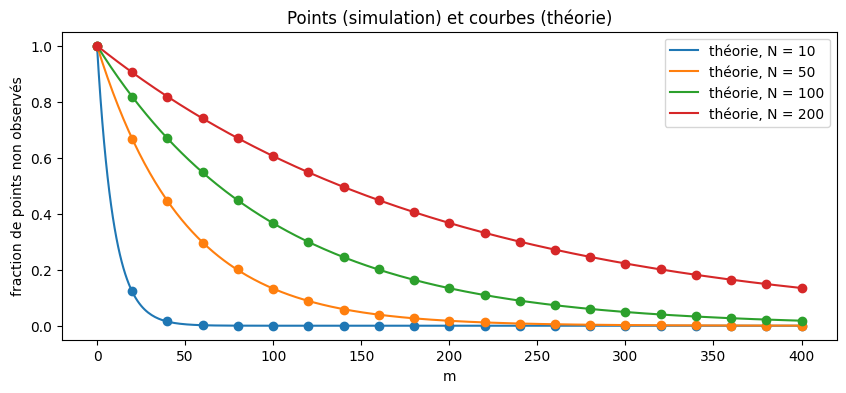

In [ ]:
N_list = [10, 50, 100, 200]
n_rep = 1000
m_list = np.arange(0, 401, 20)
m_fin = np.arange(0, 401)

print("   N      m   fraction simulée   (1-1/N)^m")
for N in N_list:
    frac_exp = []
    for m in m_list:
        fracs = []
        for r in range(n_rep):
            f = rng.integers(0, 2, N)            # (a) cible aléatoire (elle n'influence pas les points vus)
            S = rng.integers(0, N, m)            # (b) échantillon : m points tirés uniformément
            vu = np.zeros(N, dtype=bool)
            vu[S] = True                         # les points tirés sont "vus"
            fracs.append(1 - vu.mean())          # (c) fraction de points jamais observés
        frac_exp.append(np.mean(fracs))
    ligne = plt.plot(m_fin, (1 - 1 / N) ** m_fin, label=f"théorie, N = {N}")
    plt.plot(m_list, frac_exp, "o", color=ligne[0].get_color())
    for mm in [20, 100, 200]:                    # quelques valeurs pour le tableau
        j = np.where(m_list == mm)[0][0]
        print(f"{N:4d} {mm:6d} {frac_exp[j]:14.4f} {(1 - 1 / N) ** mm:14.4f}")
plt.xlabel("m")
plt.ylabel("fraction de points non observés")
plt.legend()
plt.title("Points (simulation) et courbes (théorie)")
plt.show()

**Commentaire.**
- Les points de la simulation sont sur les courbes théoriques : par exemple pour $N = 100$, $m = 100$ on trouve 0.367 contre 0.366, et pour $N = 50$, $m = 100$ on trouve 0.132 contre 0.133.
- On a $(1-1/N)^m \approx e^{-m/N}$, donc tout dépend du rapport $m/N$. Pour $m = N$ il reste environ 37 % de points non vus ($e^{-1}$), pour $m = 2N$ environ 13.5 %. Pour voir presque tout le domaine, il faut un échantillon beaucoup plus grand que $N$.

## Question 7 – Erreur sur les points non vus

**Calcul de l'espérance du risque.** Le risque est $L_D(A(S)) = \frac{1}{N}\sum_x \mathbf{1}[A(S)(x) \ne f(x)]$. Fixons $x$ :
- si $x$ est vu, l'algorithme prédit le label observé, qui est $f(x)$ (les labels sont sans bruit) : pas d'erreur ;
- si $x$ n'est pas vu, l'algorithme prédit 0, et il se trompe exactement quand $f(x) = 1$. Comme $f(x) \sim \text{Bernoulli}(1/2)$ est indépendant de l'échantillon, cela arrive avec probabilité $1/2$.

Donc $\Pr[\text{erreur en } x] = \frac{1}{2}\Pr[x \text{ non vu}] = \frac{1}{2}(1 - 1/N)^m$, et en moyennant sur $x$ :
$$\mathbb{E}[L_D(A(S))] = \frac{1}{2}\Big(1 - \frac{1}{N}\Big)^m.$$

**Méthode.** Avec $N = 100$, on simule 3 000 couples (cible, échantillon) pour chaque $m$ et on calcule le risque exact sur tout le domaine.

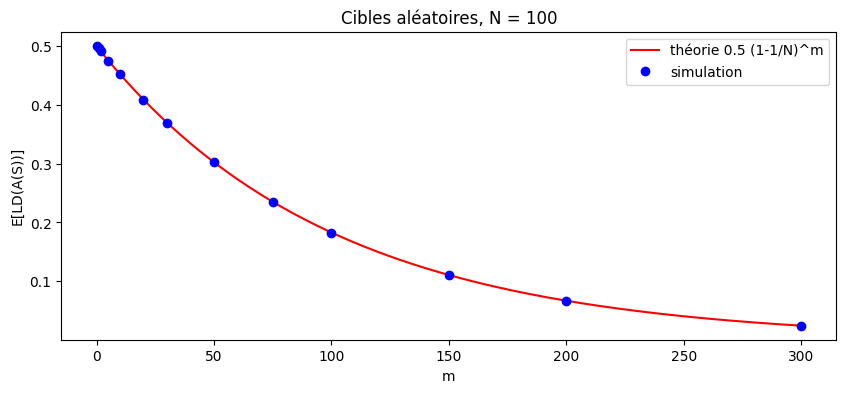

    m   simulation   théorie
    0     0.5006     0.5000
    1     0.4961     0.4950
    2     0.4914     0.4900
    5     0.4740     0.4755
   10     0.4527     0.4522
   20     0.4081     0.4090
   30     0.3692     0.3699
   50     0.3030     0.3025
   75     0.2344     0.2353
  100     0.1825     0.1830
  150     0.1105     0.1107
  200     0.0667     0.0670
  300     0.0245     0.0245


In [ ]:
def un_essai(N, m, regle="zero", p1=0.5):
    """Une répétition : cible aléatoire, échantillon, apprentissage, risque vrai sur tout le domaine.
    regle = ce qu'on prédit sur les points non vus : "zero", "un" ou "alea"
    p1 = P(f(x) = 1) ; p1 = 0.5 pour les cibles complètement aléatoires"""
    f = (rng.random(N) < p1).astype(int)       # cible : f(x) ~ Bernoulli(p1) indépendamment pour chaque x
    S = rng.integers(0, N, m)                  # échantillon de taille m (loi uniforme)
    if regle == "zero":
        pred = np.zeros(N, dtype=int)
    elif regle == "un":
        pred = np.ones(N, dtype=int)
    else:
        pred = rng.integers(0, 2, N)           # label Bernoulli(1/2) sur chaque point
    pred[S] = f[S]                             # points vus : on prédit le label observé
    return np.mean(pred != f)                  # LD(A(S)) sur tout le domaine

def risque_moyen(N, m, regle="zero", p1=0.5, n_rep=3000):
    return np.mean([un_essai(N, m, regle, p1) for _ in range(n_rep)])

N = 100
m_grid = np.array([0, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300])
risque_alea = np.array([risque_moyen(N, m) for m in m_grid])          # apprenant "prédire 0"
theorie = 0.5 * (1 - 1 / N) ** m_grid

plt.plot(np.arange(301), 0.5 * (1 - 1 / N) ** np.arange(301), "r-", label="théorie 0.5 (1-1/N)^m")
plt.plot(m_grid, risque_alea, "bo", label="simulation")
plt.xlabel("m")
plt.ylabel("E[LD(A(S))]")
plt.title(f"Cibles aléatoires, N = {N}")
plt.legend()
plt.show()

print("    m   simulation   théorie")
for m, a, b in zip(m_grid, risque_alea, theorie):
    print(f"{m:5d} {a:10.4f} {b:10.4f}")

**Commentaire.**
- La simulation et la formule sont d'accord : l'écart est inférieur à 0.002 pour toutes les valeurs de $m$ (par exemple 0.1825 contre 0.1830 pour $m = 100$, et 0.0245 contre 0.0245 pour $m = 300$).
- Pour $m = 0$ le risque vaut 0.5 : l'algorithme ne sait rien et se trompe une fois sur deux. Il ne diminue ensuite que parce que de plus en plus de points sont vus (donc appris par cœur). Pour atteindre 5 % de risque avec $N = 100$, il faut environ 230 exemples, c'est-à-dire plus que $N$.
- L'algorithme n'apprend rien sur les points non vus : il ne fait que mémoriser.

## Question 8 – Changer la prédiction sur les points non vus

**Méthode.** On compare trois règles pour les points non vus : toujours 0, toujours 1, ou un label Bernoulli(1/2) tiré au hasard. On calcule les risques moyens pour les cibles complètement aléatoires.

**Test supplémentaire.** Pour mieux comprendre le No-Free-Lunch, on regarde aussi ce qui se passe quand les cibles ne sont plus uniformément aléatoires : $f(x) \sim \text{Bernoulli}(p_1)$ avec $p_1 \in \{0.1, 0.5, 0.9\}$. La probabilité d'erreur sur un point non vu devient $p_1$ (règle « 0 »), $1 - p_1$ (règle « 1 ») ou $1/2$ (règle aléatoire).

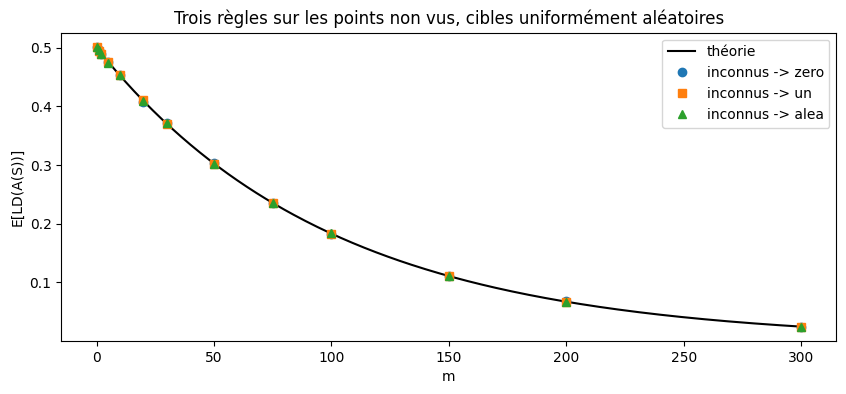

    m    zero      un       alea
    0   0.5003   0.5003   0.5014
    1   0.4952   0.4941   0.4954
    2   0.4895   0.4883   0.4897
    5   0.4760   0.4759   0.4745
   10   0.4524   0.4526   0.4527
   20   0.4076   0.4112   0.4081
   30   0.3708   0.3705   0.3710
   50   0.3026   0.3008   0.3020
   75   0.2352   0.2350   0.2344
  100   0.1830   0.1831   0.1832
  150   0.1115   0.1107   0.1108
  200   0.0674   0.0666   0.0665
  300   0.0244   0.0243   0.0245

Risque moyen pour m = 50 (entre parenthèses : théorie (1-1/N)^m x P(erreur sur un point non vu))
règle   P(f=1)=0.1          P(f=1)=0.5          P(f=1)=0.9
zero    0.0608 (0.0605)  0.3030 (0.3025)  0.5448 (0.5445)


un      0.5443 (0.5445)  0.3028 (0.3025)  0.0611 (0.0605)


alea    0.3034 (0.3025)  0.3023 (0.3025)  0.3019 (0.3025)


In [ ]:
regles = ["zero", "un", "alea"]
risques = {r: np.array([risque_moyen(N, m, regle=r) for m in m_grid]) for r in regles}

plt.plot(np.arange(301), 0.5 * (1 - 1 / N) ** np.arange(301), "k-", label="théorie")
for r, marqueur in zip(regles, ["o", "s", "^"]):
    plt.plot(m_grid, risques[r], marqueur, label=f"inconnus -> {r}")
plt.xlabel("m")
plt.ylabel("E[LD(A(S))]")
plt.title("Trois règles sur les points non vus, cibles uniformément aléatoires")
plt.legend()
plt.show()

print("    m    zero      un       alea")
for i, m in enumerate(m_grid):
    print(f"{m:5d} {risques['zero'][i]:8.4f} {risques['un'][i]:8.4f} {risques['alea'][i]:8.4f}")

# Que se passe-t-il si les cibles ne sont PAS uniformément aléatoires ? (m = 50)
print()
print("Risque moyen pour m = 50 (entre parenthèses : théorie (1-1/N)^m x P(erreur sur un point non vu))")
print("règle   P(f=1)=0.1          P(f=1)=0.5          P(f=1)=0.9")
m = 50
for r in regles:
    ligne = f"{r:6s}"
    for p1 in [0.1, 0.5, 0.9]:
        exp = risque_moyen(N, m, regle=r, p1=p1, n_rep=5000)
        perr = {"zero": p1, "un": 1 - p1, "alea": 0.5}[r]       # proba d'erreur sur un point non vu
        theo = (1 - 1 / N) ** m * perr
        ligne += f"  {exp:.4f} ({theo:.4f})"
    print(ligne)

**Commentaire.**
- Pour les cibles uniformément aléatoires, les trois règles ont le même risque moyen (pour $m = 50$ : 0.3026, 0.3008 et 0.3020, pour une théorie à 0.3025). Les petites différences viennent du bruit de simulation. **Aucune règle ne fait mieux que les autres.**
- La raison : pour un point non vu, $f(x)$ est un Bernoulli(1/2) indépendant de l'échantillon, donc quelle que soit la prédiction (même aléatoire) elle est fausse avec probabilité $1/2$.
- C'est le No-Free-Lunch : si toutes les cibles sont possibles (et également probables), l'échantillon ne donne aucune information sur les labels des points non vus, et aucun algorithme n'est meilleur qu'un autre.
- Le deuxième tableau montre l'autre côté de la médaille. Chaque règle est excellente pour une famille de cibles et mauvaise pour une autre : la règle « 0 » donne 0.061 si $p_1 = 0.1$ mais 0.545 si $p_1 = 0.9$, et la règle « 1 » fait exactement l'inverse. La règle aléatoire donne toujours environ 0.30. Prédire 0 par défaut est donc déjà une hypothèse sur le monde (un biais inductif) qui n'est bonne que si la cible a surtout des 0. Un algorithme n'est bon que par rapport aux hypothèses qu'on fait sur la cible.

---
# Partie III – Introduction d'une connaissance a priori

Même domaine $X = \{1, \dots, N\}$ ($N = 100$), mais la cible est maintenant un seuil $f_\theta(x) = \mathbf{1}[x > \theta]$ avec $\theta \in \{1, \dots, N-1\}$. La classe d'hypothèses est $H = \{h_t(x) = \mathbf{1}[x > t] : t \in \{1, \dots, N-1\}\}$, donc $|H| = N - 1$ et $f_\theta \in H$.

## Question 9 – Apprentissage avec un biais inductif adapté

**Méthode.** Pour chaque répétition : (a) on tire $\theta$ uniformément dans $\{1, \dots, N-1\}$, (b) on tire un échantillon de taille $m$, (c) on calcule l'erreur empirique de chacun des $N-1$ seuils et on choisit un seuil qui la minimise (ERM ; comme plusieurs seuils ont souvent la même erreur, on en choisit un au hasard parmi les meilleurs), (d) on calcule le vrai risque sur tout le domaine. On répète 2 000 fois pour chaque $m$.

**Référence théorique.** Comme $f_\theta \in H$, on est dans le cas réalisable, où l'ERM a une erreur empirique nulle. Un seuil dont le risque dépasse $\varepsilon$ n'est pas cohérent avec l'échantillon avec probabilité au moins $1 - (1-\varepsilon)^m$, donc par l'union $\Pr[L_D(h_S) > \varepsilon] \le |H| e^{-\varepsilon m}$. En intégrant :
$$\mathbb{E}[L_D(h_S)] = \int_0^1 \Pr[L_D(h_S) > \varepsilon]\, d\varepsilon \le \int_0^1 \min(1, |H|e^{-\varepsilon m})\, d\varepsilon \le \frac{\ln|H|}{m} + \frac{1}{m} = \frac{1 + \ln|H|}{m}.$$
On trace cette borne en rouge.

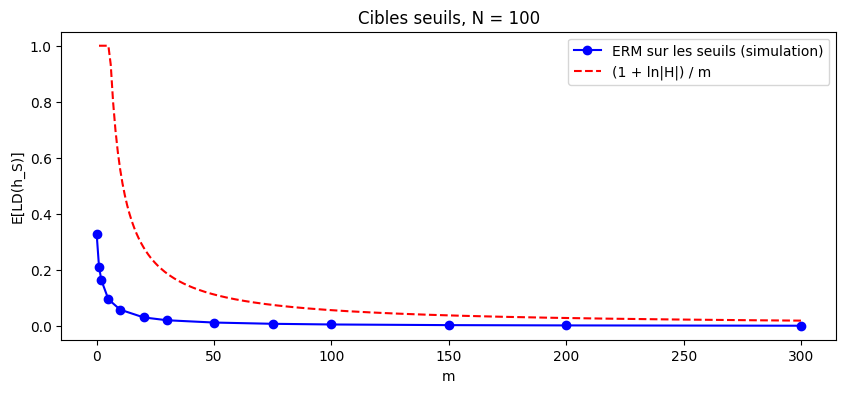

    m   E[LD(h_S)]
    0     0.3287
    1     0.2118
    2     0.1630
    5     0.0948
   10     0.0579
   20     0.0302
   30     0.0200
   50     0.0118
   75     0.0073
  100     0.0049
  150     0.0026
  200     0.0016
  300     0.0005


In [ ]:
x_dom = np.arange(1, N + 1)          # domaine X = {1, ..., N}
t_list = np.arange(1, N)             # seuils possibles t = 1, ..., N-1

def erm_seuil(S, y):
    """ERM sur les seuils : renvoie un t qui minimise l'erreur empirique (égalités tranchées au hasard)."""
    pred = (S[:, None] > t_list[None, :]).astype(int)    # matrice m x (N-1) : prédiction de chaque seuil
    err = (pred != y[:, None]).sum(axis=0)               # nombre d'erreurs de chaque seuil
    candidats = np.flatnonzero(err == err.min())         # tous les seuils ERM
    return t_list[rng.choice(candidats)]

def un_essai_seuil(N, m):
    theta = rng.integers(1, N)                           # cible f_theta, theta dans {1, ..., N-1}
    S = rng.integers(1, N + 1, m)                        # échantillon uniforme sur X
    y = (S > theta).astype(int)                          # labels observés
    t = erm_seuil(S, y)                                  # apprentissage
    return np.mean((x_dom > t) != (x_dom > theta))       # vrai risque sur tout le domaine

n_rep = 2000
risque_seuil = np.array([np.mean([un_essai_seuil(N, m) for _ in range(n_rep)]) for m in m_grid])

m_fin = np.arange(1, 301)
plt.plot(m_grid, risque_seuil, "bo-", label="ERM sur les seuils (simulation)")
plt.plot(m_fin, np.minimum(1, (1 + np.log(N - 1)) / m_fin), "r--", label="(1 + ln|H|) / m")
plt.xlabel("m")
plt.ylabel("E[LD(h_S)]")
plt.title(f"Cibles seuils, N = {N}")
plt.legend()
plt.show()

print("    m   E[LD(h_S)]")
for m, r in zip(m_grid, risque_seuil):
    print(f"{m:5d} {r:10.4f}")

**Commentaire.**
- Pour $m = 0$ le risque vaut 0.329, soit environ $1/3$ : c'est l'écart moyen entre deux seuils tirés au hasard. Ensuite il décroît très vite : 0.058 pour $m = 10$, 0.0049 pour $m = 100$, 0.0005 pour $m = 300$. Il décroît à peu près comme $1/m$.
- La borne $(1 + \ln|H|)/m$ est valide (elle est toujours au-dessus) mais très conservative : pour $m = 100$, elle donne 0.056 contre 0.0049 en simulation, soit un facteur 11. Les seuils voisins se ressemblent beaucoup (deux seuils consécutifs ne diffèrent que sur un point), et l'union sur 99 hypothèses ne le sait pas.
- Comparaison avec la Partie II : avec $m = 100$ exemples, le risque moyen est de 0.183 pour des cibles aléatoires, mais de 0.005 pour des cibles seuils. L'algorithme n'est pas meilleur, c'est le problème qui est plus structuré.

## Question 10 – Cibles aléatoires contre cibles structurées

On trace sur le même graphique le risque moyen en fonction de $m$ pour les cibles complètement aléatoires (Q7) et pour les cibles seuils (Q9), à gauche en échelle linéaire et à droite en échelle logarithmique.

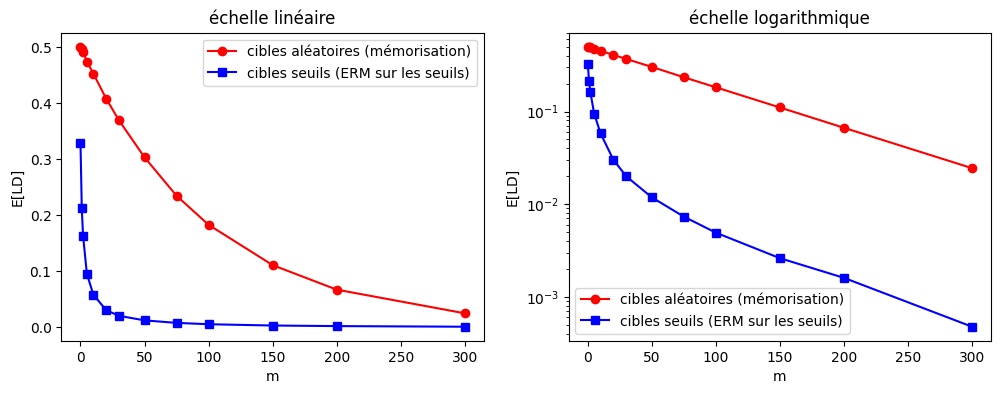

cibles aléatoire : risque moyen < 5 % dès m = 300  (plus petit m de la grille)
cibles seuil : risque moyen < 5 % dès m = 20  (plus petit m de la grille)
cibles aléatoires, théorie : m >= 230


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax in axes:
    ax.plot(m_grid, risque_alea, "ro-", label="cibles aléatoires (mémorisation)")
    ax.plot(m_grid, risque_seuil, "bs-", label="cibles seuils (ERM sur les seuils)")
    ax.set_xlabel("m")
    ax.set_ylabel("E[LD]")
    ax.legend()
axes[0].set_title("échelle linéaire")
axes[1].set_yscale("log")
axes[1].set_title("échelle logarithmique")
plt.show()

# plus petit m de la grille pour lequel le risque moyen passe sous 5 %
for nom, courbe in [("aléatoire", risque_alea), ("seuil", risque_seuil)]:
    m_ok = m_grid[np.where(courbe < 0.05)[0][0]]
    print(f"cibles {nom} : risque moyen < 5 % dès m = {m_ok}  (plus petit m de la grille)")
# valeur exacte pour les cibles aléatoires : 0.5 (1-1/N)^m < 0.05
print("cibles aléatoires, théorie : m >=", int(np.ceil(np.log(0.05 / 0.5) / np.log(1 - 1 / N))))

**Commentaire.**
- Avec les cibles seuils, le risque moyen passe sous 5 % dès $m = 20$, alors que pour les cibles aléatoires il faut $m \ge 230$ (valeur exacte) : environ 10 fois plus d'exemples pour $N = 100$. Et l'écart se creuse quand $N$ augmente : pour les cibles aléatoires, $m$ doit croître comme $N$, alors que pour les seuils la borne ne dépend de $N$ que par $\ln N$.
- **Pourquoi le deuxième cas généralise mieux.** Dans le cas des cibles aléatoires, les labels des différents points sont indépendants : voir un point ne dit rien des autres, donc il faut avoir vu chaque point. Dans le cas des seuils, un seul exemple renseigne sur beaucoup de points : si on voit $f(x) = 0$, alors $x \le \theta$ et tous les points $x' \le x$ sont aussi de label 0 ; si on voit $f(x) = 1$, tous les points $x' \ge x$ sont de label 1. L'échantillon enferme donc $\theta$ dans un intervalle (de longueur environ $N/m$), et l'ERM choisit un seuil dans cet intervalle, d'où un risque de l'ordre de $1/m$.
- **Rôle de l'hypothèse « la cible est un seuil ».** C'est elle qui fait le travail : elle ramène le nombre de cibles possibles de $2^N$ à $N - 1$, ce qui rend les labels des points fortement dépendants entre eux. Sans elle (Q7), les labels des points non vus sont indépendants de l'échantillon. C'est exactement ce qu'on appelle un biais inductif. Le prix à payer : si la vraie cible n'est pas un seuil, la garantie n'est plus valable (ce cas n'est pas testé ici).

---
# Question 11 – Conclusion

- **Concentration de $L_S(h)$ autour de $L_D(h)$.** $L_S(h)$ est la moyenne de $m$ variables de Bernoulli indépendantes : sa variance vaut $p(1-p)/m$ (Q1), et Hoeffding donne une probabilité de dévier de plus de $\varepsilon$ qui décroît comme $e^{-2m\varepsilon^2}$ (Q2). Plus $m$ est grand, plus $L_S(h)$ est concentré.
- **Pourquoi contrôler toutes les hypothèses en même temps.** L'algorithme (ERM) choisit $h$ *après* avoir vu l'échantillon, donc l'hypothèse choisie peut très bien être justement celle qui s'est trompée. Il faut que $|L_S(h) - L_D(h)| \le \varepsilon$ soit vrai pour tous les $h$ à la fois, c'est-à-dire $\Delta_S \le \varepsilon$. La Q3 montre que c'est plus difficile que pour une seule hypothèse fixée.
- **Effet de $|H|$.** Plus $|H|$ est grand, plus il y a de chances qu'une hypothèse s'écarte (borne de l'union : un facteur $|H|$). Mais comme la décroissance en $m$ est exponentielle, le $m$ nécessaire n'augmente que comme $\ln|H|$ : $|H|$ multiplié par 100 donne un $m$ multiplié par 2.4 seulement (Q4 et Q5).
- **Pourquoi les bornes sont conservatives.** Hoeffding ne tient pas compte de la variance et perd un facteur polynomial (Q2 : jusqu'à 20 fois trop grande) ; l'union additionne des événements rares et qui ne sont pas tous aussi probables (Q3 : 20 à 30 fois trop grande) ; et la borne doit marcher pour toutes les distributions. Le $m$ théorique est environ 1.5 à 1.9 fois trop grand (Q5) : le facteur est bien plus petit que sur la probabilité, parce que $m$ est dans un exposant. Les bornes sont des *garanties suffisantes*, pas des valeurs exactes.
- **Cibles aléatoires et points non vus.** Avec des cibles complètement aléatoires, les labels des points non vus sont indépendants de l'échantillon, donc impossibles à prévoir : l'erreur vaut $1/2$ sur ces points, et $\mathbb{E}[L_D(A(S))] = \frac{1}{2}(1-1/N)^m$ (Q6 et Q7).
- **No-Free-Lunch.** Les trois règles de la Q8 ont le même risque quand toutes les cibles sont possibles, et chaque règle perd sur une famille de cibles ce qu'elle gagne sur une autre. Un algorithme ne peut donc pas déduire des labels arbitraires non vus à partir du seul échantillon : il faut une hypothèse sur la cible.
- **Les seuils comme connaissance a priori.** En supposant que la cible et les hypothèses sont des seuils, on passe de $2^N$ cibles possibles à $N - 1$ : les labels des points ne sont plus indépendants.
- **Pourquoi cela permet de généraliser.** Un exemple renseigne alors sur plein d'autres points, et le risque décroît comme $1/m$ (0.005 pour $m = 100$ contre 0.18 en cibles aléatoires). C'est le rôle du biais inductif : il choisit à l'avance quelles généralisations sont possibles, et c'est ce qui permet d'apprendre au-delà des exemples vus.